# CSE558 Midterm Project: Did the 2020 lockdown clear India's air?
**Name:** Shubham Kumar Yadav (2023516)

Dataset: CPCB hourly air quality data from Kaggle (`rohanrao/air-quality-data-in-india`, file `station_hour.csv`). I am using my cleaned pickle file `station_hour_clean.pkl`.

**Plan of this notebook**
1. Dataset and size check
2. Data preparation (duplicates, missing values, sensor ceiling values, outliers, AQI scale, encoding)
3. Before and after the preparation
4. EDA and problem statements
5. Hypothesis tests (5 tests)
6. Summary with multiple testing correction

All numbers are stored in a dictionary `R` and saved to `results.json` at the end. Figures are saved in the `figs` folder as jpg files.

The next cell installs `statsmodels` (needed for the ANOVA and power calculations). It does nothing if it is already installed.

In [9]:
%pip install -q statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\SHUBHAM YADAV\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import TTestPower, TTestIndPower
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

# folder for the figures
os.makedirs("figs", exist_ok=True)

# size of the original Kaggle file (station_hour.csv)
original_rows = 2589083
original_cols = 16

# R will store every result so that I can use it later in the report
R = {}

# fixed seed so permutation tests give the same answer each time
rng = np.random.default_rng(558)

# list of pollutants used in the project
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene"]

# colours for the plots
RED = "#c0392b"
GREEN = "#2a9d5c"
BLUE = "#3b7dd8"

plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False})

## 1. Dataset and size check

In [11]:
%pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\SHUBHAM YADAV\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [12]:
%pip install --upgrade kagglehub truststore

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\SHUBHAM YADAV\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [13]:
# Use Windows' certificate store for the Kaggle HTTPS connection
import truststore
truststore.inject_into_ssl()

import kagglehub
import pandas as pd
from pathlib import Path

# Download the public Kaggle dataset
dataset_folder = Path(
    kagglehub.dataset_download("rohanrao/air-quality-data-in-india")
)

# Find and load the hourly station data
csv_file = dataset_folder / "station_hour.csv"

if not csv_file.exists():
    raise FileNotFoundError(f"Could not find the dataset file: {csv_file}")

data = pd.read_csv(csv_file)

print("Loaded file:", csv_file)
print("Data shape:", data.shape)
data.head()

Loaded file: C:\Users\SHUBHAM YADAV\.cache\kagglehub\datasets\rohanrao\air-quality-data-in-india\versions\12\station_hour.csv
Data shape: (2589083, 16)


,StationId,Datetime,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24 17:00:00,60.50,98.00,2.35,30.80,18.25,8.50,0.1,11.85,126.40,0.1,6.10,0.10,NaN,NaN
1,AP001,2017-11-24 18:00:00,65.50,111.25,2.70,24.20,15.07,9.77,0.1,13.17,117.12,0.1,6.25,0.15,NaN,NaN
2,AP001,2017-11-24 19:00:00,80.00,132.00,2.10,25.18,15.15,12.02,0.1,12.08,98.98,0.2,5.98,0.18,NaN,NaN
3,AP001,2017-11-24 20:00:00,81.50,133.25,1.95,16.25,10.23,11.58,0.1,10.47,112.20,0.2,6.72,0.10,NaN,NaN
4,AP001,2017-11-24 21:00:00,75.25,116.00,1.43,17.48,10.43,12.03,0.1,9.12,106.35,0.2,5.75,0.08,NaN,NaN


The Kaggle `station_hour.csv` only has `StationId` and `Datetime`. I get `City` from `stations.csv`, map each state to a `Region`, and work out the `Season` from the month.

In [14]:
# the Kaggle file has StationId and Datetime only, so I add City, Region and Season myself
data["Datetime"] = pd.to_datetime(data["Datetime"])

# City and State come from stations.csv (same Kaggle folder)
stations = pd.read_csv(dataset_folder / "stations.csv")
data = data.merge(stations[["StationId", "City", "State"]], on="StationId", how="left")

# group the states into 4 regions
region_of_state = {
    "Delhi": "North", "Haryana": "North", "Punjab": "North", "Chandigarh": "North",
    "Uttar Pradesh": "North", "Rajasthan": "North",
    "Andhra Pradesh": "South", "Karnataka": "South", "Kerala": "South",
    "Tamil Nadu": "South", "Telangana": "South",
    "Assam": "East", "Bihar": "East", "Jharkhand": "East", "Meghalaya": "East",
    "Mizoram": "East", "Odisha": "East", "West Bengal": "East",
    "Gujarat": "West", "Maharashtra": "West", "Madhya Pradesh": "West",
}
data["Region"] = data["State"].map(region_of_state)
data = data.drop(columns="State")

# Indian seasons from the month
season_of_month = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "PreMonsoon", 4: "PreMonsoon", 5: "PreMonsoon",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "PostMonsoon", 11: "PostMonsoon",
}
data["Season"] = data["Datetime"].dt.month.map(season_of_month)

print("Data shape:", data.shape)
data[["StationId", "City", "Region", "Season"]].head(3)

Data shape: (2589083, 19)


,StationId,City,Region,Season
0,AP001,Amaravati,South,PostMonsoon
1,AP001,Amaravati,South,PostMonsoon
2,AP001,Amaravati,South,PostMonsoon


In [15]:
# basic facts about the dataset
rows_received = len(data)
cols_received = original_cols             # columns of the Kaggle file
number_of_stations = data["StationId"].nunique()
number_of_cities = data["City"].nunique()
first_time = data["Datetime"].min()
last_time = data["Datetime"].max()

R["asrecv_rows"] = rows_received
R["asrecv_cols"] = cols_received
R["raw_rows"] = original_rows
R["raw_cols"] = original_cols
R["stations"] = int(number_of_stations)
R["cities"] = int(number_of_cities)
R["t0"] = str(first_time)
R["t1"] = str(last_time)
R["regions"] = data.groupby("Region")["StationId"].nunique().to_dict()

print("Stations:", number_of_stations)
print("Cities:", number_of_cities)
print("Time range:", first_time, "to", last_time)
print()

# size check: instances x attributes must be at least 3 million
raw_size = original_rows * original_cols
received_size = rows_received * cols_received
print("Original Kaggle file:", original_rows, "x", original_cols, "=", raw_size)
print("Encoded file        :", rows_received, "x", cols_received, "=", received_size)
print("At least 3,000,000 ?", received_size >= 3000000)

Stations: 110
Cities: 26
Time range: 2015-01-01 01:00:00 to 2020-07-01 00:00:00

Original Kaggle file: 2589083 x 16 = 41425328
Encoded file        : 2589083 x 16 = 41425328
At least 3,000,000 ? True


**Some important features and what they mean in real life**

| Feature | Type | Meaning |
|---|---|---|
| `PM2.5` | continuous | tiny particles (smaller than 2.5 micrometre) in µg/m³, they go deep in the lungs. This is our main response variable |
| `PM10` | continuous | coarser dust and particles in µg/m³ |
| `NO2` | continuous | nitrogen dioxide in µg/m³, comes from vehicles and burning fuel |
| `AQI` | continuous | official Air Quality Index of CPCB, from 0 to 500 |
| `AQI_Bucket` | ordinal | Good, Satisfactory, Moderate, Poor, Very Poor, Severe (I encode it as 0 to 5) |
| `StationId`, `City` | nominal | monitoring station (110) and its city (26) |
| `Region`, `Season` | nominal | region of India (from the state) and season of the year (from the month) |
| `IsWeekend` | binary | 1 for Saturday and Sunday (I create it) |
| `*_imputed` | binary | 1 if I filled in that pollutant value (I create it) |

## 2. Data preparation

Problems I look for in the raw Kaggle file and what I do about them:

| Problem | What I do | Why |
|---|---|---|
| Wrong data types | parse `Datetime`, make categories | needed for time features and to save memory |
| Duplicate rows | drop duplicates of (station, time) | one hour should be counted only once |
| Empty rows | drop rows where every pollutant and AQI is missing | they carry no information |
| Impossible values | negative concentrations become missing | a concentration cannot be below zero |
| Sensor ceiling values (like 999.99) | change them to missing | the instrument just reached its limit, it is not a real reading |
| Very high values | cap at the 99.9th percentile | these are real smog days so I keep the rows, but they should not control the mean |
| AQI above 500, inconsistent bucket | cap at 500 and rebuild the bucket from AQI | the AQI scale ends at 500 |
| Missing values | fill short gaps (up to 3 hours) per station by time interpolation, flag them, tests use only observed values | short gaps are safe to interpolate, long gaps are not |
| Encoding | ordinal AQI bucket, one hot City / Region / Season, time features | needed for grouping, models and the lockdown window |

First I record how the data looks **before** any of these steps.

In [16]:
# keep a copy of the original PM2.5 so I can compare later
original_pm25 = data["PM2.5"].copy()

# duplicates and empty rows
duplicate_count = data.duplicated(subset=["StationId", "Datetime"]).sum()
empty_row_count = data[pollutants + ["AQI"]].isna().all(axis=1).sum()

# impossible values
negative_count = (data[pollutants] < 0).sum().sum()

# PM2.5 problems
pm25_missing_count = data["PM2.5"].isna().sum()
pm25_ceiling_count = (data["PM2.5"] >= 999).sum()
pm25_maximum = data["PM2.5"].max()
pm25_skewness = data["PM2.5"].skew()
pm25_kurtosis = data["PM2.5"].kurt()
pm25_p999 = data["PM2.5"].quantile(0.999)

# AQI problems
aqi_over_500_count = (data["AQI"] > 500).sum()
aqi_maximum = data["AQI"].max()

# missing values over all pollutants
missing_cells_count = data[pollutants].isna().sum().sum()
total_pollutant_cells = len(data) * len(pollutants)

before_summary = {
    "dup": int(duplicate_count),
    "empty_rows": int(empty_row_count),
    "negatives": int(negative_count),
    "pm_nan": int(pm25_missing_count),
    "pm_sat": int(pm25_ceiling_count),
    "pm_max": float(pm25_maximum),
    "pm_skew": float(pm25_skewness),
    "pm_kurt": float(pm25_kurtosis),
    "pm_p999": float(pm25_p999),
    "aqi_gt500": int(aqi_over_500_count),
    "aqi_max": float(aqi_maximum),
    "cells_nan": int(missing_cells_count),
    "n_cells": int(total_pollutant_cells),
    "pm_usable": int(data["PM2.5"].notna().sum()),
}

R["before"] = before_summary
print(before_summary)

{'dup': 0, 'empty_rows': 236926, 'negatives': 0, 'pm_nan': 647689, 'pm_sat': 666, 'pm_max': 1000.0, 'pm_skew': 3.344411675462465, 'pm_kurt': 18.30545803386413, 'pm_p999': 853.6517500000191, 'aqi_gt500': 43761, 'aqi_max': 3133.0, 'cells_nan': 7406642, 'n_cells': 25890830, 'pm_usable': 1941394}


In [17]:
# missing values for every pollutant in the raw file
missing_table = pd.DataFrame()
missing_table["missing"] = data[pollutants].isna().sum()
missing_table["missing_pct"] = (100 * missing_table["missing"] / len(data)).round(1)

R["missing"] = missing_table.to_dict(orient="index")
missing_table

,missing,missing_pct
PM2.5,647689,25.0
PM10,1119252,43.2
NO,553711,21.4
NO2,528973,20.4
NOx,490808,19.0
NH3,1236618,47.8
CO,499302,19.3
SO2,742737,28.7
O3,725973,28.0
Benzene,861579,33.3


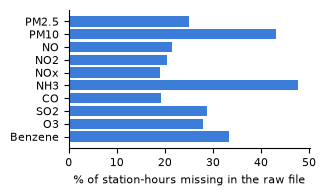

In [18]:
# bar chart of the missing percentage per pollutant
fig, ax = plt.subplots(figsize=(3.3, 2.0))
ax.barh(missing_table.index, missing_table["missing_pct"], color=BLUE)
ax.invert_yaxis()
ax.set_xlabel("% of station-hours missing in the raw file")
plt.tight_layout()
plt.savefig("figs/fig_missing.jpg", dpi=300)
plt.show()

**Step 1: data types, duplicates and empty rows**

In [19]:
# categories use much less memory than text
for column_name in ["StationId", "City", "Region", "Season", "AQI_Bucket"]:
    data[column_name] = data[column_name].astype("category")

rows_before = len(data)
data = data.drop_duplicates(subset=["StationId", "Datetime"])
duplicates_removed = rows_before - len(data)

# rows where nothing at all was measured
is_empty = data[pollutants + ["AQI"]].isna().all(axis=1)
empty_removed = int(is_empty.sum())
data = data[~is_empty]

# sort so that interpolation later goes forward in time for each station
data = data.sort_values(["StationId", "Datetime"]).reset_index(drop=True)

print("Duplicate rows removed:", duplicates_removed)
print("Empty rows removed    :", empty_removed)
print("Rows left             :", len(data))
data.dtypes

Duplicate rows removed: 0
Empty rows removed    : 236926
Rows left             : 2352157


StationId           category
Datetime      datetime64[us]
PM2.5                float64
PM10                 float64
NO                   float64
NO2                  float64
NOx                  float64
NH3                  float64
CO                   float64
SO2                  float64
O3                   float64
Benzene              float64
Toluene              float64
Xylene               float64
AQI                  float64
AQI_Bucket          category
City                category
Region              category
Season              category
dtype: object

**Step 2: impossible values and sensor ceiling values.** A concentration cannot be negative, so those become missing. Some readings are stuck at the maximum the instrument can show (for example 999.99 for PM2.5). These are not real measurements so I make them missing too.

In [20]:
negatives_removed = {}
ceiling_removed = {}

for pollutant in pollutants:
    is_negative = data[pollutant] < 0
    negatives_removed[pollutant] = int(is_negative.sum())
    data.loc[is_negative, pollutant] = np.nan

    max_value = data[pollutant].max()

    # PM2.5, PM10 and O3 are always checked, other pollutants only if their maximum is very large
    is_special = pollutant in ["PM2.5", "PM10", "O3"]
    has_large_maximum = max_value >= 499

    if is_special or has_large_maximum:
        limit = 0.998 * max_value
        is_ceiling = data[pollutant] >= limit
        ceiling_removed[pollutant] = int(is_ceiling.sum())
        data.loc[is_ceiling, pollutant] = np.nan

print("Negative readings changed to missing:")
print(negatives_removed)
print("Ceiling readings changed to missing:")
print(ceiling_removed)

Negative readings changed to missing:
{'PM2.5': 0, 'PM10': 0, 'NO': 0, 'NO2': 0, 'NOx': 0, 'NH3': 0, 'CO': 0, 'SO2': 0, 'O3': 0, 'Benzene': 0}
Ceiling readings changed to missing:
{'PM2.5': 669, 'PM10': 461, 'NO': 43, 'NO2': 7, 'NOx': 52, 'NH3': 3, 'O3': 3}


**Step 3: very high values.** Real smog days can be really high, so I do not delete these rows. I only cap each pollutant at its 99.9th percentile so a few extreme hours cannot control the average.

In [21]:
capped_values = {}

for pollutant in pollutants:
    upper_limit = data[pollutant].quantile(0.999)
    number_above = int((data[pollutant] > upper_limit).sum())
    capped_values[pollutant] = number_above
    data[pollutant] = data[pollutant].clip(upper=upper_limit)

print("Values capped at the 99.9th percentile:")
print(capped_values)

Values capped at the 99.9th percentile:
{'PM2.5': 1941, 'PM10': 1470, 'NO': 2036, 'NO2': 2061, 'NOx': 2099, 'NH3': 1353, 'CO': 2090, 'SO2': 1847, 'O3': 1864, 'Benzene': 1728}


**Step 4: AQI and AQI bucket.** The official AQI scale stops at 500 but some rows have much bigger numbers. After capping I rebuild the bucket from the AQI value using the CPCB cut points, so the two columns always agree, and encode the bucket as an ordinal number.

In [22]:
print("AQI maximum before:", data["AQI"].max())
data["AQI"] = data["AQI"].clip(upper=500)
print("AQI maximum after :", data["AQI"].max())

# CPCB buckets: 0-50, 51-100, 101-200, 201-300, 301-400, 401-500
bucket_names = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
new_bucket = pd.cut(data["AQI"], bins=[-1, 50, 100, 200, 300, 400, 500], labels=bucket_names)

has_both = data["AQI_Bucket"].notna() & new_bucket.notna()
bucket_mismatch = int((data["AQI_Bucket"].astype(str) != new_bucket.astype(str))[has_both].sum())
print("Rows where the bucket did not match the AQI:", bucket_mismatch)

# ordinal code 0 (Good) to 5 (Severe), missing stays missing
data["AQI_Bucket"] = new_bucket
data["AQI_Bucket_ord"] = new_bucket.cat.codes.astype(float)
data["AQI_Bucket_ord"] = data["AQI_Bucket_ord"].where(data["AQI_Bucket_ord"] >= 0)

AQI maximum before: 3133.0
AQI maximum after : 500.0
Rows where the bucket did not match the AQI: 0


**Step 5: missing values.** Pollutant values change smoothly from one hour to the next, so a gap of 1 to 3 hours can be filled safely by time interpolation inside the same station. Longer gaps stay missing because guessing them would invent data. Every filled value gets a flag `*_imputed = 1`, and the hypothesis tests use only observed values (`PM2.5_obs`, `NO2_obs`).

In [23]:
# remember which values were really measured
was_missing = data[pollutants].isna()

# fill gaps of at most 3 hours inside each station (data is sorted by station and time)
filled_parts = []
for station_id, station_data in data.groupby("StationId", observed=True, sort=False):
    station_data = station_data.set_index("Datetime")
    filled = station_data[pollutants].interpolate(method="time", limit=3, limit_area="inside")
    filled_parts.append(filled.values)
data[pollutants] = np.vstack(filled_parts)

imputed_counts = {}
for pollutant in pollutants:
    is_imputed = was_missing[pollutant] & data[pollutant].notna()
    data[pollutant + "_imputed"] = is_imputed.astype(np.uint8)
    imputed_counts[pollutant] = int(is_imputed.sum())

missing_table["imputed"] = pd.Series(imputed_counts)
missing_table["still_missing"] = data[pollutants].isna().sum()
missing_table["still_missing_pct"] = (100 * missing_table["still_missing"] / len(data)).round(1)
R["missing"] = missing_table.to_dict(orient="index")
missing_table

,missing,missing_pct,imputed,still_missing,still_missing_pct
PM2.5,647689,25.0,46302,365130,15.5
PM10,1119252,43.2,34358,848429,36.1
NO,553711,21.4,47683,269145,11.4
NO2,528973,20.4,41305,250749,10.7
NOx,490808,19.0,34533,219401,9.3
NH3,1236618,47.8,26912,972783,41.4
CO,499302,19.3,60692,201684,8.6
SO2,742737,28.7,55200,450611,19.2
O3,725973,28.0,37620,451430,19.2
Benzene,861579,33.3,30968,593685,25.2


**Step 6: new features and encoding.** I add the time features, the Delhi NCR and lockdown flags needed by the tests, and one hot columns for City, Region and Season.

In [24]:
# observed only columns (imputed values removed)
data["PM2.5_obs"] = data["PM2.5"].where(data["PM2.5_imputed"] == 0)
data["NO2_obs"] = data["NO2"].where(data["NO2_imputed"] == 0)

# time features
data["Date"] = data["Datetime"].dt.normalize()
data["Year"] = data["Datetime"].dt.year
data["Hour"] = data["Datetime"].dt.hour
data["IsWeekend"] = (data["Datetime"].dt.dayofweek >= 5).astype(np.uint8)

# 1 if the station is in Delhi or Gurugram (Delhi NCR)
is_ncr = data["City"].isin(["Delhi", "Gurugram"])
data["DelhiNCR"] = is_ncr.astype(np.uint8)

# 1 if the hour is inside the lockdown window (25 March to 30 June 2020)
after_start = data["Datetime"] >= "2020-03-25"
before_end = data["Datetime"] < "2020-07-01"
data["LockdownWin"] = (after_start & before_end).astype(np.uint8)

# one hot encoding of the nominal columns (the label columns are kept for grouping)
one_hot = pd.get_dummies(data[["City", "Region", "Season"]], prefix=["City", "Region", "Season"], dtype=np.uint8)
data = pd.concat([data, one_hot], axis=1)

print("Observed PM2.5 hours:", data["PM2.5_obs"].notna().sum())
print("Rows inside lockdown window:", data["LockdownWin"].sum())
print("One hot columns added:", one_hot.shape[1])
print("Data shape:", data.shape)

Observed PM2.5 hours: 1940725
Rows inside lockdown window: 236131
One hot columns added: 34
Data shape: (2352157, 72)


## 3. Before and after the preparation

In [25]:
after_summary = {}
after_summary["rows"] = len(data)
after_summary["cols"] = data.shape[1] - 3      # 3 label columns are not counted
after_summary["pm_sat"] = int((data["PM2.5"] >= 999).sum())
after_summary["pm_max"] = float(data["PM2.5"].max())
after_summary["pm_skew"] = float(data["PM2.5"].skew())
after_summary["pm_kurt"] = float(data["PM2.5"].kurt())
after_summary["aqi_max"] = float(data["AQI"].max())
after_summary["dup"] = int(data.duplicated(subset=["StationId", "Datetime"]).sum())
after_summary["negatives"] = int((data[pollutants] < 0).sum().sum())
after_summary["cells_nan"] = int(data[pollutants].isna().sum().sum())
after_summary["cells_imputed"] = int(sum(imputed_counts.values()))
after_summary["pm_obs"] = int(data["PM2.5_obs"].notna().sum())
after_summary["pm_obs_share"] = float(data["PM2.5_obs"].notna().mean())
after_summary["n_capped_pm"] = capped_values["PM2.5"]
after_summary["n_capped_all"] = int(sum(capped_values.values()))

R["after"] = after_summary
R["n_capped"] = capped_values
R["size_before"] = original_rows * original_cols
R["size_after"] = after_summary["rows"] * after_summary["cols"]

# comparison table
comparison = pd.DataFrame({
    "Measure": ["Rows", "Columns", "Duplicate rows", "Negative readings", "Missing pollutant cells",
                "PM2.5 ceiling readings", "PM2.5 maximum",
                "PM2.5 skewness", "PM2.5 kurtosis", "AQI maximum", "Observed PM2.5 hours"],
    "Before": [rows_received, cols_received, before_summary["dup"], before_summary["negatives"],
               before_summary["cells_nan"], before_summary["pm_sat"],
               round(before_summary["pm_max"], 2), round(before_summary["pm_skew"], 2),
               round(before_summary["pm_kurt"], 1), before_summary["aqi_max"], before_summary["pm_usable"]],
    "After": [after_summary["rows"], after_summary["cols"], after_summary["dup"], after_summary["negatives"],
              after_summary["cells_nan"], after_summary["pm_sat"],
              round(after_summary["pm_max"], 2), round(after_summary["pm_skew"], 2),
              round(after_summary["pm_kurt"], 1), after_summary["aqi_max"], after_summary["pm_obs"]],
})
print(comparison.to_string(index=False))
print()

print("Size check after preparation:")
print(after_summary["rows"], "x", after_summary["cols"], "=", R["size_after"])
print("At least 3,000,000 ?", R["size_after"] >= 3000000)

                Measure     Before      After
                   Rows 2589083.00 2352157.00
                Columns      16.00      69.00
         Duplicate rows       0.00       0.00
      Negative readings       0.00       0.00
Missing pollutant cells 7406642.00 4623047.00
 PM2.5 ceiling readings     666.00       0.00
          PM2.5 maximum    1000.00     787.01
         PM2.5 skewness       3.34       3.00
         PM2.5 kurtosis      18.30      13.30
            AQI maximum    3133.00     500.00
   Observed PM2.5 hours 1941394.00 1940725.00

Size check after preparation:
2352157 x 69 = 162298833
At least 3,000,000 ? True


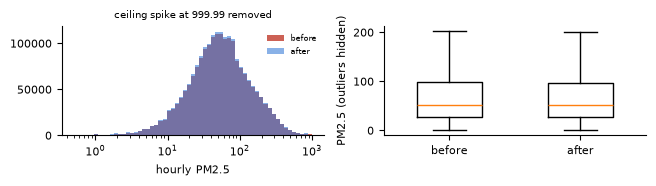

In [26]:
# histogram and boxplot of PM2.5, before and after cleaning
fig, ax = plt.subplots(1, 2, figsize=(6.6, 1.9))

bins = np.geomspace(0.5, 1000, 60)
ax[0].hist(original_pm25.dropna(), bins=bins, color=RED, alpha=0.8, label="before")
ax[0].hist(data["PM2.5"].dropna(), bins=bins, color=BLUE, alpha=0.6, label="after")
ax[0].set_xscale("log")
ax[0].set_xlabel("hourly PM2.5")
ax[0].set_title("ceiling spike at 999.99 removed", fontsize=7)
ax[0].legend(frameon=False, fontsize=6)

ax[1].boxplot([original_pm25.dropna(), data["PM2.5"].dropna()], tick_labels=["before", "after"], showfliers=False, widths=0.5)
ax[1].set_ylabel("PM2.5 (outliers hidden)")

plt.tight_layout()
plt.savefig("figs/fig_before_after.jpg", dpi=300)
plt.show()

**What changed:** duplicate and completely empty rows are gone, negative readings and the artificial ceiling spike at 999.99 are now missing, extreme values are capped at the 99.9th percentile, AQI stops at 500 and its bucket agrees with it, short gaps of up to 3 hours are filled and flagged, and every hypothesis test uses only real (observed) readings. The exact numbers are in the table above.

## 4. EDA and problem statements

In [27]:
pm_values = data["PM2.5_obs"].dropna()

# average PM2.5 of every city, highest first
city_average = data.groupby("City")["PM2.5_obs"].mean()
city_average = city_average.sort_values(ascending=False)

# average by season, by hour and by year
season_average = data.groupby("Season")["PM2.5_obs"].mean().round(1)
hour_average = data.groupby("Hour")["PM2.5_obs"].mean()
year_average = data.groupby("Year")["PM2.5_obs"].mean().round(1)

# correlation of PM2.5 and PM10
pm_pair = data[["PM2.5_obs", "PM10"]].dropna()
correlation = pm_pair.corr().iloc[0, 1]

# number of Delhi stations in every year
delhi_data = data[data["City"] == "Delhi"]
delhi_stations = delhi_data.groupby("Year")["StationId"].nunique()

R["eda"] = {
    "pm_median": float(pm_values.median()),
    "pm_mean": float(pm_values.mean()),
    "pm_skew": float(pm_values.skew()),
    "share_gt60": float((pm_values > 60).mean()),
    "n_obs": int(len(pm_values)),
    "top_city": city_average.head(3).round(1).to_dict(),
    "low_city": city_average.tail(2).round(1).to_dict(),
    "corr_pm": float(correlation),
    "season": season_average.to_dict(),
    "hour_peak": int(hour_average.idxmax()),
    "hour_low": int(hour_average.idxmin()),
    "yearly": year_average.to_dict(),
    "delhi_st": delhi_stations.to_dict(),
}

print("Median PM2.5:", round(pm_values.median(), 1))
print("Share of hours above 60:", round((pm_values > 60).mean(), 3))
print("Top 3 cities:", R["eda"]["top_city"])
print("Cleanest cities:", R["eda"]["low_city"])
print("By season:", R["eda"]["season"])
print("Hour with highest PM2.5:", R["eda"]["hour_peak"], " lowest:", R["eda"]["hour_low"])
print("PM2.5 and PM10 correlation:", round(correlation, 2))
print("By year:", R["eda"]["yearly"])

Median PM2.5: 52.6
Share of hours above 60: 0.442
Top 3 cities: {'Delhi': 110.5, 'Lucknow': 108.8, 'Patna': 103.3}
Cleanest cities: {'Ernakulam': 25.2, 'Aizawl': 19.4}
By season: {'Monsoon': 39.5, 'PostMonsoon': 119.5, 'PreMonsoon': 61.7, 'Winter': 124.3}
Hour with highest PM2.5: 23  lowest: 17
PM2.5 and PM10 correlation: 0.84
By year: {2015: 87.1, 2016: 98.0, 2017: 104.8, 2018: 89.6, 2019: 78.2, 2020: 57.6}


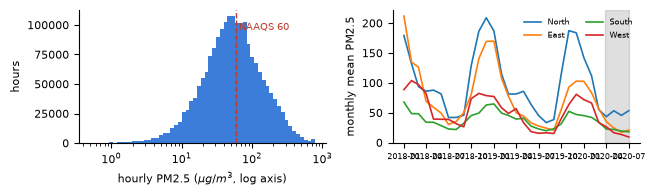

In [28]:
# EDA figure 1: distribution of PM2.5 and monthly trend by region
fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.0))

ax[0].hist(pm_values, bins=np.geomspace(0.5, pm_values.max(), 60), color=BLUE)
ax[0].set_xscale("log")
ax[0].axvline(60, color=RED, linestyle="--", linewidth=1)
ax[0].text(65, ax[0].get_ylim()[1] * 0.85, "NAAQS 60", color=RED, fontsize=7)
ax[0].set_xlabel(r"hourly PM2.5 ($\mu g/m^3$, log axis)")
ax[0].set_ylabel("hours")

# monthly average per region from 2018
recent = data[data["Year"] >= 2018].copy()
recent["Month"] = recent["Datetime"].dt.to_period("M").dt.to_timestamp()
monthly = recent.groupby(["Month", "Region"])["PM2.5_obs"].mean().unstack()

for region_name in ["North", "East", "South", "West"]:
    ax[1].plot(monthly.index, monthly[region_name], label=region_name, linewidth=1.2)

ax[1].axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-07-01"), color="grey", alpha=0.25)
ax[1].set_ylabel("monthly mean PM2.5")
ax[1].legend(fontsize=6, ncol=2, frameon=False)
ax[1].tick_params(axis="x", labelsize=6)

plt.tight_layout()
plt.savefig("figs/fig_eda.jpg", dpi=300)
plt.show()

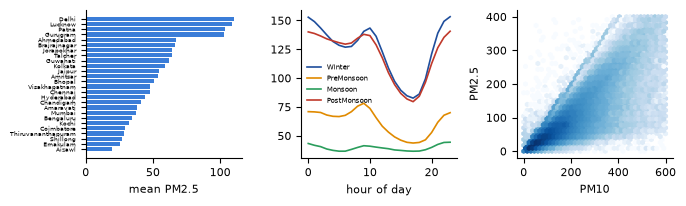

In [29]:
# EDA figure 2: cities, hour of the day by season, PM2.5 vs PM10
fig, ax = plt.subplots(1, 3, figsize=(6.9, 2.1))

city_sorted = city_average.sort_values()
ax[0].barh(city_sorted.index, city_sorted.values, color=BLUE)
ax[0].tick_params(axis="y", labelsize=4.5)
ax[0].set_xlabel("mean PM2.5")

season_names = ["Winter", "PreMonsoon", "Monsoon", "PostMonsoon"]
season_colours = ["#1f4e9c", "#e08a00", GREEN, RED]

for i in range(4):
    one_season = data[data["Season"] == season_names[i]]
    hourly = one_season.groupby("Hour")["PM2.5_obs"].mean()
    ax[1].plot(hourly.index, hourly.values, label=season_names[i], color=season_colours[i], linewidth=1.2)

ax[1].set_xlabel("hour of day")
ax[1].legend(fontsize=5, frameon=False)

# a random sample is enough for the hexbin plot
sample = pm_pair.sample(200000, random_state=1)
ax[2].hexbin(sample["PM10"], sample["PM2.5_obs"], gridsize=40, bins="log", mincnt=1, cmap="Blues", extent=(0, 600, 0, 400))
ax[2].set_xlabel("PM10")
ax[2].set_ylabel("PM2.5")

plt.tight_layout()
plt.savefig("figs/fig_eda2.jpg", dpi=300)
plt.show()

**Takeaways**
* PM2.5 is strongly right skewed: the median is about 53 but 44% of hours are above the national limit of 60.
* Post monsoon and winter are the worst seasons and the North is the worst region.
* PM2.5 and PM10 move together (correlation 0.82).
* All regions drop during the grey lockdown window of 2020.

**Basic questions:** (1) Which city is the dirtiest? (2) When is the air worst? (3) Do PM2.5 and PM10 move together?

**Our problem statements** (each can come out either way)
* **P1 (main):** Was station level PM2.5 lower in the lockdown window (25 Mar to 30 Jun 2020) than in the same window of 2019?
* **P2:** In winter 2019-20, is PM2.5 higher at Delhi NCR stations than at other northern cities?
* **P3:** Do mean PM2.5 levels differ between North, East, South and West in 2019?
* **P4:** Is NO2 lower on weekends than on weekdays (before the lockdown)?
* **P5:** Did the share of days above 60 µg/m³ fall in the lockdown window compared to 2019?

**Why they are new:** the basic questions look at one slice of the data. These compare against a counter window (same station, same dates, one year earlier) or against groups made from new features (`LockdownWin`, `DelhiNCR`).

## 5. Hypothesis tests
**Unit of analysis.** Hourly values of one station are strongly related to each other (see the autocorrelation below) so hours are **not** independent. Because of this, every test uses one number per station (Tests 1 to 4) or one matched station-day (Test 5).

In [30]:
# find the station with most observations and check how much an hour looks like the previous hour
busiest_station = data["StationId"].value_counts().index[0]
busiest_data = data[data["StationId"] == busiest_station]
busiest_data = busiest_data.sort_values("Datetime")
pm_series = busiest_data["PM2.5_obs"]

lag1 = pm_series.autocorr(1)
R["lag1_autocorr"] = float(lag1)
print("Lag-1 autocorrelation of hourly PM2.5 at the busiest station:", round(lag1, 3))

Lag-1 autocorrelation of hourly PM2.5 at the busiest station: 0.779


In [31]:
# ---------- helper functions used by the tests ----------

def mean_confidence_interval(values, confidence=0.95):
    # confidence interval for a mean using the t distribution
    n = len(values)
    mean = values.mean()
    standard_error = values.std(ddof=1) / np.sqrt(n)
    t_value = stats.t.ppf(0.5 + confidence / 2, n - 1)
    lower = mean - t_value * standard_error
    upper = mean + t_value * standard_error
    return lower, upper


def bootstrap_ci(values, repeats=10000):
    # confidence interval of the mean by resampling the data again and again
    means = []
    for i in range(repeats):
        resample = rng.choice(values, len(values))
        means.append(resample.mean())
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    return float(lower), float(upper)


def welch_test(group_a, group_b, alternative):
    # Welch t-test (does not assume equal variance)
    group_a = np.asarray(group_a, dtype=float)
    group_b = np.asarray(group_b, dtype=float)
    result = stats.ttest_ind(group_a, group_b, equal_var=False, alternative=alternative)
    var_a = group_a.var(ddof=1) / len(group_a)
    var_b = group_b.var(ddof=1) / len(group_b)
    degrees = (var_a + var_b) ** 2 / (var_a ** 2 / (len(group_a) - 1) + var_b ** 2 / (len(group_b) - 1))
    difference = group_a.mean() - group_b.mean()
    standard_error = np.sqrt(var_a + var_b)
    t_value = stats.t.ppf(0.975, degrees)
    lower = difference - t_value * standard_error
    upper = difference + t_value * standard_error
    return float(result.statistic), float(degrees), float(result.pvalue), float(difference), float(lower), float(upper), float(standard_error)


def sign_flip_p_value(differences, alternative, repeats=20000):
    # permutation test for paired data: randomly flip the sign of every difference
    observed = differences.mean()
    signs = rng.choice([-1, 1], size=(repeats, len(differences)))
    flipped_means = (signs * differences).mean(axis=1)
    if alternative == "less":
        count = (flipped_means <= observed).sum()
    else:
        count = (flipped_means >= observed).sum()
    return float((count + 1) / (repeats + 1))


def get_window(year, start, end):
    # all rows between two dates (like "03-25" and "07-01") of a given year
    start_time = str(year) + "-" + start
    end_time = str(year) + "-" + end
    after_start = data["Datetime"] >= start_time
    before_end = data["Datetime"] < end_time
    return data[after_start & before_end]

### Test 1 (P1, main): lockdown vs the same window of 2019, paired t-test
* **H0:** μ2020 − μ2019 ≥ 0  **H1:** μ2020 − μ2019 < 0
* α = 0.05, one sided (left). Smallest difference that matters: **10 µg/m³**.
* Unit: mean PM2.5 of a station from 25 March to 30 June (observed hours only). A station needs at least 1,200 observed hours in both years.
* Why paired: the same station is measured in both years, so the level of the station cancels out.

In [32]:
def station_means(year, start, end):
    # mean PM2.5 and number of observed hours for every station in a window
    window_data = get_window(year, start, end)
    grouped = window_data.groupby("StationId")["PM2.5_obs"]
    result = grouped.agg(["mean", "count"])
    return result


def run_test1(baseline_year=2019, min_hours=1200, drop_delhi=False, start="03-25", end="07-01"):
    baseline = station_means(baseline_year, start, end)
    lockdown = station_means(2020, start, end)

    table = baseline.join(lockdown, lsuffix="_base", rsuffix="_2020")
    table = table.dropna()

    enough_base = table["count_base"] >= min_hours
    enough_2020 = table["count_2020"] >= min_hours
    table = table[enough_base & enough_2020]

    if drop_delhi:
        ncr_stations = data[data["DelhiNCR"] == 1]["StationId"].unique()
        table = table[~table.index.isin(ncr_stations)]

    differences = (table["mean_2020"] - table["mean_base"]).values
    t_result = stats.ttest_rel(table["mean_2020"], table["mean_base"], alternative="less")
    lower, upper = mean_confidence_interval(differences)
    return table, differences, t_result, lower, upper


table1, diff1, t_result1, low1, high1 = run_test1()

# city of every station
station_city = data.groupby("StationId")["City"].first()
table1["city"] = station_city.reindex(table1.index)

n1 = len(diff1)
sd1 = diff1.std(ddof=1)

# log scale (gives a percentage change)
log_ratio = np.log(table1["mean_2020"] / table1["mean_base"]).values
log_low, log_high = mean_confidence_interval(log_ratio)

# other tests to compare with
wilcoxon_result = stats.wilcoxon(table1["mean_2020"], table1["mean_base"], alternative="less")
stations_fell = int((diff1 < 0).sum())
sign_result = stats.binomtest(stations_fell, n1, 0.5, alternative="greater")
welch1 = welch_test(table1["mean_2020"].values, table1["mean_base"].values, "less")
shapiro1 = stats.shapiro(diff1)

# same test on city averages (stations of one city are not independent)
city_means = table1.groupby("city")[["mean_base", "mean_2020"]].mean()
city_t = stats.ttest_rel(city_means["mean_2020"], city_means["mean_base"], alternative="less")
city_difference = (city_means["mean_2020"] - city_means["mean_base"]).mean()

# practical test: is the drop bigger than 10 ?
practical1 = stats.ttest_1samp(diff1, -10, alternative="less")

# power and smallest detectable difference
power_tool = TTestPower()
power1 = power_tool.power(effect_size=10 / sd1, nobs=n1, alpha=0.05, alternative="larger")
mde1 = power_tool.solve_power(effect_size=None, nobs=n1, alpha=0.05, power=0.8, alternative="larger") * sd1

R["T1"] = {
    "n": n1,
    "m19": float(table1["mean_base"].mean()),
    "m20": float(table1["mean_2020"].mean()),
    "est": float(diff1.mean()),
    "lo": float(low1),
    "hi": float(high1),
    "t": float(t_result1.statistic),
    "df": n1 - 1,
    "p": float(t_result1.pvalue),
    "dz": float(diff1.mean() / sd1),
    "pct": float((np.exp(log_ratio.mean()) - 1) * 100),
    "pct_lo": float((np.exp(log_low) - 1) * 100),
    "pct_hi": float((np.exp(log_high) - 1) * 100),
    "boot": bootstrap_ci(diff1),
    "wil_p": float(wilcoxon_result.pvalue),
    "sign_p": float(sign_result.pvalue),
    "sign_k": stations_fell,
    "welch_t": welch1[0],
    "welch_df": welch1[1],
    "welch_p": welch1[2],
    "shapiro_p": float(shapiro1.pvalue),
    "skew_d": float(stats.skew(diff1)),
    "ncity": len(city_means),
    "city_est": float(city_difference),
    "city_t": float(city_t.statistic),
    "city_p": float(city_t.pvalue),
    "ztest_z": float(diff1.mean() / (sd1 / np.sqrt(n1))),
    "perm_p": sign_flip_p_value(diff1, "less"),
    "prac_t": float(practical1.statistic),
    "prac_p": float(practical1.pvalue),
    "power": float(power1),
    "mde": float(mde1),
    "sd_d": float(sd1),
}

print("Stations used:", n1)
print("Mean 2019 window:", round(R["T1"]["m19"], 1), " Mean 2020 lockdown:", round(R["T1"]["m20"], 1))
print("Estimate:", round(R["T1"]["est"], 2), " 95% CI:", round(low1, 2), "to", round(high1, 2))
print("t =", round(R["T1"]["t"], 2), " df =", n1 - 1, " p =", R["T1"]["p"])
print("Percentage change:", round(R["T1"]["pct"], 1), "%")
print("Welch p:", R["T1"]["welch_p"], " Wilcoxon p:", R["T1"]["wil_p"], " Sign test p:", R["T1"]["sign_p"])
print("Sign flip permutation p:", R["T1"]["perm_p"], " Bootstrap CI:", R["T1"]["boot"])
print("Shapiro p of differences:", round(R["T1"]["shapiro_p"], 5))
print("Practical test (drop bigger than 10): p =", R["T1"]["prac_p"])
print("Power:", round(R["T1"]["power"], 3), " smallest detectable drop:", round(R["T1"]["mde"], 2))
print("City level test: estimate", round(R["T1"]["city_est"], 2), " p =", R["T1"]["city_p"])

Stations used: 71
Mean 2019 window: 63.0  Mean 2020 lockdown: 38.8
Estimate: -24.24  95% CI: -27.94 to -20.55
t = -13.09  df = 70  p = 8.645040375744732e-21
Percentage change: -38.1 %
Welch p: 6.26642973132569e-11  Wilcoxon p: 1.5688560330341763e-13  Sign test p: 3.049318610115481e-20
Sign flip permutation p: 4.999750012499375e-05  Bootstrap CI: (-27.944640170329468, -20.761470042741298)
Shapiro p of differences: 0.0002
Practical test (drop bigger than 10): p = 3.403393518660929e-11
Power: 1.0  smallest detectable drop: 4.65
City level test: estimate -17.17  p = 3.9437465348971415e-05


In [33]:
# sensitivity: does the answer change if I change my choices?
sens1 = []

def add_sensitivity1(label, **options):
    table, differences, t_result, lower, upper = run_test1(**options)
    row = {
        "label": label,
        "n": len(table),
        "est": float(differences.mean()),
        "lo": float(lower),
        "hi": float(upper),
        "p": float(t_result.pvalue),
    }
    sens1.append(row)

add_sensitivity1("main (2019, >=1200 h)")
add_sensitivity1(">=600 h", min_hours=600)
add_sensitivity1(">=1800 h", min_hours=1800)
add_sensitivity1("baseline 2018", baseline_year=2018)
add_sensitivity1("window 1 Apr-30 Jun", start="04-01", end="07-01")
add_sensitivity1("excluding Delhi-NCR", drop_delhi=True)

R["sens1"] = sens1
pd.DataFrame(sens1).round(4)

,label,n,est,lo,hi,p
0,"main (2019, >=1200 h)",71,-24.2426,-27.9366,-20.5485,0.0
1,>=600 h,77,-22.8425,-26.4344,-19.2507,0.0
2,>=1800 h,56,-25.8508,-29.9703,-21.7314,0.0
3,baseline 2018,52,-31.9283,-37.3500,-26.5067,0.0
4,window 1 Apr-30 Jun,70,-23.2199,-26.9040,-19.5358,0.0
5,excluding Delhi-NCR,34,-16.0526,-19.9441,-12.1611,0.0


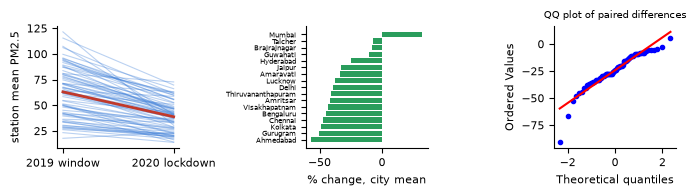

city
Ahmedabad            -56.584725
Gurugram             -50.735959
Kolkata              -48.513158
Chennai              -46.890235
Bengaluru            -44.802522
Visakhapatnam        -43.088050
Amritsar             -41.795756
Thiruvananthapuram   -40.968803
Delhi                -39.167526
Lucknow              -37.891310
Amaravati            -33.988294
Jaipur               -33.210042
Hyderabad            -24.980731
Guwahati             -10.780734
Brajrajnagar          -8.297768
Talcher               -7.571096
Mumbai                32.012630
dtype: float64

In [34]:
# change in every city, and the figures of Test 1
city_change = (city_means["mean_2020"] / city_means["mean_base"] - 1) * 100
city_change = city_change.sort_values()
R["city_change"] = city_change.round(1).to_dict()

fig, ax = plt.subplots(1, 3, figsize=(6.9, 2.0))

# left: one line for every station
for i in range(len(table1)):
    before_value = table1["mean_base"].iloc[i]
    after_value = table1["mean_2020"].iloc[i]
    ax[0].plot([0, 1], [before_value, after_value], color=BLUE, alpha=0.35, linewidth=0.8)

ax[0].plot([0, 1], [table1["mean_base"].mean(), table1["mean_2020"].mean()], color=RED, linewidth=2)
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["2019 window", "2020 lockdown"])
ax[0].set_ylabel("station mean PM2.5")

# middle: change of every city
ax[1].barh(city_change.index, city_change.values, color=GREEN)
ax[1].tick_params(axis="y", labelsize=5)
ax[1].set_xlabel("% change, city mean")

# right: QQ plot to check if the differences look normal
stats.probplot(diff1, dist="norm", plot=ax[2])
ax[2].set_title("QQ plot of paired differences", fontsize=7)
ax[2].get_lines()[0].set_markersize(3)

plt.tight_layout()
plt.savefig("figs/fig_t1.jpg", dpi=300)
plt.show()

city_change

**Test 1 result.** PM2.5 fell by about 24 µg/m³ (38%). Almost every station fell, the drop is much bigger than the 10 µg/m³ we said would matter, and the result stays the same when I change the coverage, the window or the baseline year. Without Delhi NCR the drop is still 16 µg/m³. Only Mumbai went up.

*Other tests I considered:* Welch t-test (ignores the pairing so it is weaker), z-test (needs known σ), Wilcoxon signed rank (no normality needed), sign test (ignores the size of the change), sign flip permutation test, bootstrap interval and a city level t-test. All of them agree with the paired t-test.

### Test 2 (P2): Delhi NCR vs other northern cities in winter 2019-20, Welch t-test
* **H0:** μNCR − μother ≤ 0  **H1:** μNCR − μother > 0
* α = 0.05, one sided (right). Smallest difference that matters: **15 µg/m³**.
* Unit: mean PM2.5 of a station from 1 Dec 2019 to 29 Feb 2020 (same winter for everybody), at least 1,000 observed hours.

In [35]:
def run_test2(min_hours=1000, start="2019-12-01", end="2020-03-01"):
    after_start = data["Datetime"] >= start
    before_end = data["Datetime"] < end
    in_north = data["Region"] == "North"
    north_winter = data[after_start & before_end & in_north]

    grouped = north_winter.groupby("StationId")
    table = pd.DataFrame()
    table["pm"] = grouped["PM2.5_obs"].mean()
    table["n"] = grouped["PM2.5_obs"].count()
    table["ncr"] = grouped["DelhiNCR"].first()
    table["city"] = grouped["City"].first()

    table = table[table["n"] >= min_hours]
    return table


table2 = run_test2()
group_ncr = table2[table2["ncr"] == 1]["pm"].values
group_other = table2[table2["ncr"] == 0]["pm"].values

t2, df2, p2, diff2, low2, high2, se2 = welch_test(group_ncr, group_other, "greater")

# other tests
pooled_result = stats.ttest_ind(group_ncr, group_other, equal_var=True, alternative="greater")
levene_result = stats.levene(group_ncr, group_other)
mannwhitney_result = stats.mannwhitneyu(group_ncr, group_other, alternative="greater")
z_value = diff2 / se2
z_p_value = 1 - stats.norm.cdf(z_value)

# permutation test: shuffle the group labels many times
all_values = np.concatenate([group_ncr, group_other])
permuted_differences = []
for i in range(20000):
    shuffled = rng.permutation(all_values)
    first_part = shuffled[:len(group_ncr)]
    second_part = shuffled[len(group_ncr):]
    permuted_differences.append(first_part.mean() - second_part.mean())
permuted_differences = np.array(permuted_differences)
perm_count = (permuted_differences >= diff2).sum()
perm_p2 = (perm_count + 1) / (20000 + 1)

# practical test: is the gap bigger than 15 ?
practical_t2 = (diff2 - 15) / se2
practical_p2 = 1 - stats.t.cdf(practical_t2, df2)

# power
var_ncr = group_ncr.var(ddof=1)
var_other = group_other.var(ddof=1)
pooled_sd = np.sqrt(((len(group_ncr) - 1) * var_ncr + (len(group_other) - 1) * var_other) / (len(group_ncr) + len(group_other) - 2))
power_tool2 = TTestIndPower()
ratio = len(group_other) / len(group_ncr)
power2 = power_tool2.power(effect_size=15 / pooled_sd, nobs1=len(group_ncr), ratio=ratio, alpha=0.05, alternative="larger")
mde2 = power_tool2.solve_power(effect_size=None, nobs1=len(group_ncr), ratio=ratio, alpha=0.05, power=0.8, alternative="larger") * pooled_sd

other_cities = sorted(table2[table2["ncr"] == 0]["city"].unique().tolist())

R["T2"] = {
    "na": len(group_ncr),
    "nb": len(group_other),
    "ma": float(group_ncr.mean()),
    "mb": float(group_other.mean()),
    "t": t2,
    "df": df2,
    "p": p2,
    "est": diff2,
    "lo": low2,
    "hi": high2,
    "pooled_t": float(pooled_result.statistic),
    "pooled_p": float(pooled_result.pvalue),
    "lev_p": float(levene_result.pvalue),
    "mw_p": float(mannwhitney_result.pvalue),
    "z_p": float(z_p_value),
    "sd_a": float(group_ncr.std(ddof=1)),
    "sd_b": float(group_other.std(ddof=1)),
    "cities": other_cities,
    "d_cohen": float(diff2 / np.sqrt((var_ncr + var_other) / 2)),
    "perm_p": float(perm_p2),
    "prac_t": float(practical_t2),
    "prac_p": float(practical_p2),
    "shapiro_a": float(stats.shapiro(group_ncr).pvalue),
    "shapiro_b": float(stats.shapiro(group_other).pvalue),
    "power": float(power2),
    "mde": float(mde2),
}

print("Stations: NCR =", len(group_ncr), " other north =", len(group_other), "(", other_cities, ")")
print("Means:", round(group_ncr.mean(), 1), "and", round(group_other.mean(), 1))
print("Difference:", round(diff2, 2), " 95% CI:", round(low2, 2), "to", round(high2, 2))
print("Welch t =", round(t2, 2), " df =", round(df2, 1), " p =", p2)
print("Pooled t =", round(R["T2"]["pooled_t"], 2), " Levene p =", round(R["T2"]["lev_p"], 3), " Mann-Whitney p =", R["T2"]["mw_p"])
print("Permutation p:", R["T2"]["perm_p"], " Practical test p:", round(R["T2"]["prac_p"], 4))
print("Power at 15:", round(power2, 2), " smallest detectable gap:", round(mde2, 1))

Stations: NCR = 38  other north = 9 ( ['Amritsar', 'Chandigarh', 'Jaipur', 'Lucknow'] )
Means: 159.9 and 87.6
Difference: 72.28  95% CI: 36.5 to 108.06
Welch t = 4.53  df = 9.6  p = 0.000612011239169766
Pooled t = 6.0  Levene p = 0.135  Mann-Whitney p = 0.0001534372823318626
Permutation p: 4.999750012499375e-05  Practical test p: 0.0026
Power at 15: 0.34  smallest detectable gap: 30.4


In [36]:
# sensitivity for Test 2
sens2 = []

def add_sensitivity2(label, **options):
    table = run_test2(**options)
    first = table[table["ncr"] == 1]["pm"].values
    second = table[table["ncr"] == 0]["pm"].values
    result = welch_test(first, second, "greater")
    row = {
        "label": label,
        "na": len(first),
        "nb": len(second),
        "est": result[3],
        "lo": result[4],
        "hi": result[5],
        "p": result[2],
    }
    sens2.append(row)

add_sensitivity2("main (>=1000 h)")
add_sensitivity2(">=500 h", min_hours=500)
add_sensitivity2(">=1500 h", min_hours=1500)
add_sensitivity2("winter 2018-19", start="2018-12-01", end="2019-03-01")

R["sens2"] = sens2
pd.DataFrame(sens2).round(4)

,label,na,nb,est,lo,hi,p
0,main (>=1000 h),38,9,72.2801,36.5035,108.0568,0.0006
1,>=500 h,38,9,72.2801,36.5035,108.0568,0.0006
2,>=1500 h,38,9,72.2801,36.5035,108.0568,0.0006
3,winter 2018-19,39,8,76.6553,28.6700,124.6406,0.0031


**Test 2 result.** Delhi NCR stations are about 72 µg/m³ higher than other northern cities in winter. The gap is far bigger than 15 µg/m³ (although with only 9 comparison stations the test could not reliably detect a gap as small as 15). The same result appears in winter 2018-19, so it is not a one winter accident.

*Other tests:* z-test (needs known σ), pooled t-test (equal variance not guaranteed and groups are very unequal in size), paired t-test (no pairs), Mann-Whitney U (ranks only), permutation test.

### Test 3 (P3): four regions in 2019, Welch's one-way ANOVA
* **H0:** μNorth = μEast = μSouth = μWest  **H1:** at least one mean is different
* α = 0.05. Smallest difference that matters: **10 µg/m³** between two regions.
* Unit: mean PM2.5 of a station in 2019 with at least 4,000 observed hours. Central and North East have only one station each so they are left out.

In [37]:
year_2019 = data[data["Year"] == 2019]
grouped = year_2019.groupby("StationId")

table3 = pd.DataFrame()
table3["pm"] = grouped["PM2.5_obs"].mean()
table3["n"] = grouped["PM2.5_obs"].count()
table3["region"] = grouped["Region"].first()
table3 = table3[table3["n"] >= 4000]

R["T3_all_regions"] = table3["region"].value_counts().to_dict()

region_names = ["North", "East", "South", "West"]
table3 = table3[table3["region"].isin(region_names)]

# one list of station means for every region
groups = []
for region_name in region_names:
    values = table3[table3["region"] == region_name]["pm"].values
    groups.append(values.astype(float))

# main test: Welch ANOVA
welch_anova = anova_oneway(groups, use_var="unequal", welch_correction=True)

# other tests
classic_anova = stats.f_oneway(*groups)
kruskal_result = stats.kruskal(*groups)
levene3 = stats.levene(*groups)

# effect size (eta squared and omega squared)
all_values = np.concatenate(groups)
grand_mean = all_values.mean()
ss_between = 0
for g in groups:
    ss_between = ss_between + len(g) * (g.mean() - grand_mean) ** 2
ss_total = ((all_values - grand_mean) ** 2).sum()
k = len(groups)
N = len(all_values)
ms_within = (ss_total - ss_between) / (N - k)
omega2 = (ss_between - (k - 1) * ms_within) / (ss_total + ms_within)
eta2 = ss_between / ss_total

# permutation test on Welch's F: shuffle the region labels 5000 times
labels = []
for i in range(k):
    labels = labels + [i] * len(groups[i])
labels = np.array(labels)
observed_F = float(welch_anova.statistic)

count_bigger = 0
for i in range(5000):
    shuffled = rng.permutation(all_values)
    shuffled_groups = []
    for j in range(k):
        shuffled_groups.append(shuffled[labels == j])
    shuffled_F = anova_oneway(shuffled_groups, use_var="unequal", welch_correction=True).statistic
    if shuffled_F >= observed_F:
        count_bigger = count_bigger + 1
perm_p3 = (count_bigger + 1) / (5000 + 1)

# Games-Howell test: compares every pair of regions
games_howell = []
for i in range(k):
    for j in range(i + 1, k):
        var_i = groups[i].var(ddof=1) / len(groups[i])
        var_j = groups[j].var(ddof=1) / len(groups[j])
        se = np.sqrt(var_i + var_j)
        df = (var_i + var_j) ** 2 / (var_i ** 2 / (len(groups[i]) - 1) + var_j ** 2 / (len(groups[j]) - 1))
        gap = groups[i].mean() - groups[j].mean()
        q_value = abs(gap) / se * np.sqrt(2)
        p_value = stats.studentized_range.sf(q_value, k, df)
        critical = stats.studentized_range.ppf(0.95, k, df) / np.sqrt(2)
        lower = gap - critical * se
        upper = gap + critical * se
        games_howell.append((region_names[i], region_names[j], float(gap), float(lower), float(upper), float(p_value)))

# Bonferroni corrected pairwise t-tests (for comparison)
bonferroni_p = []
for i in range(k):
    for j in range(i + 1, k):
        pair_result = stats.ttest_ind(groups[i], groups[j], equal_var=False)
        corrected = min(1, pair_result.pvalue * 6)
        bonferroni_p.append(corrected)

# normality of residuals
residuals = []
for g in groups:
    residuals.extend(g - g.mean())

largest_gap = 0
for g in groups:
    for h in groups:
        gap = abs(g.mean() - h.mean())
        if gap > largest_gap:
            largest_gap = gap

R["T3"] = {
    "ns": [len(g) for g in groups],
    "means": [float(g.mean()) for g in groups],
    "sds": [float(g.std(ddof=1)) for g in groups],
    "regs": region_names,
    "F": float(welch_anova.statistic),
    "df1": float(welch_anova.df_num),
    "df2": float(welch_anova.df_denom),
    "p": float(welch_anova.pvalue),
    "F_cl": float(classic_anova.statistic),
    "p_cl": float(classic_anova.pvalue),
    "dfw": int(N - k),
    "H": float(kruskal_result.statistic),
    "p_kw": float(kruskal_result.pvalue),
    "lev_p": float(levene3.pvalue),
    "omega2": float(omega2),
    "eta2": float(eta2),
    "gh": games_howell,
    "bonf_min": float(min(bonferroni_p)),
    "maxgap": float(largest_gap),
    "perm_p": float(perm_p3),
    "shapiro_resid": float(stats.shapiro(residuals).pvalue),
    "shapiro_by": [float(stats.shapiro(g).pvalue) for g in groups],
}

print("Stations per region:", R["T3"]["ns"])
print("Means:", [round(m, 1) for m in R["T3"]["means"]])
print("Welch F(", R["T3"]["df1"], ",", round(R["T3"]["df2"], 1), ") =", round(R["T3"]["F"], 1), " p =", R["T3"]["p"])
print("Classic F =", round(R["T3"]["F_cl"], 1), " Kruskal H =", round(R["T3"]["H"], 1), " Levene p =", round(R["T3"]["lev_p"], 3))
print("omega squared:", round(omega2, 3), " permutation p:", R["T3"]["perm_p"])
print()
pd.DataFrame(games_howell, columns=["region A", "region B", "gap", "lower", "upper", "p (Games-Howell)"]).round(4)

Stations per region: [47, 9, 20, 9]
Means: [102.5, 65.4, 39.4, 37.8]
Welch F( 3.0 , 22.4 ) = 104.5  p = 2.611653792327569e-13
Classic F = 77.0  Kruskal H = 57.3  Levene p = 0.061
omega squared: 0.728  permutation p: 0.0001999600079984003



,region A,region B,gap,lower,upper,p (Games-Howell)
0,North,East,37.0166,15.5306,58.5027,0.0013
1,North,South,63.0945,53.5793,72.6097,0.0000
2,North,West,64.6546,51.7787,77.5305,0.0000
3,East,South,26.0778,5.0235,47.1322,0.0162
4,East,West,27.6380,5.7184,49.5576,0.0128
5,South,West,1.5601,-10.0535,13.1738,0.9782


**Test 3 result.** The regions are very different (ω² = 0.73, so regions explain about 73% of the variation between stations). North is higher than every other region by more than 10 µg/m³. East is higher than South and West by about 28 to 30 µg/m³, but the lower ends of those intervals are below 10, so the size is uncertain. South and West cannot be told apart.

*Other tests:* classic ANOVA (needs equal variance, Levene rejects this), Kruskal-Wallis (ranks), six separate t-tests (more false alarms, so Bonferroni or Games-Howell is needed), permutation test on Welch's F.

### Test 4 (P4): weekend vs weekday NO2, paired t-test (before the lockdown)
* **H0:** μweekend − μweekday ≥ 0  **H1:** μweekend − μweekday < 0
* α = 0.05, one sided (left). Smallest difference that matters: **5 µg/m³**.
* Data before 25 March 2020, observed NO2 only. A station needs at least 1,000 weekday and 500 weekend hours.
* Since I want to show the effect is *small*, I also do a TOST equivalence test with limits ±5 µg/m³.

In [38]:
def run_test4(min_weekday=1000, min_weekend=500, drop_delhi=False):
    before_lockdown = data[data["Datetime"] < "2020-03-25"]
    grouped = before_lockdown.groupby(["StationId", "IsWeekend"])["NO2_obs"]
    table = grouped.agg(["mean", "count"]).unstack()
    table = table.dropna()

    enough_weekday = table[("count", 0)] >= min_weekday
    enough_weekend = table[("count", 1)] >= min_weekend
    table = table[enough_weekday & enough_weekend]

    if drop_delhi:
        ncr_stations = data[data["DelhiNCR"] == 1]["StationId"].unique()
        table = table[~table.index.isin(ncr_stations)]

    weekday_means = table[("mean", 0)].values.astype(float)
    weekend_means = table[("mean", 1)].values.astype(float)
    return weekday_means, weekend_means


weekday, weekend = run_test4()
diff4 = weekend - weekday
n4 = len(diff4)
sd4 = diff4.std(ddof=1)

t_result4 = stats.ttest_rel(weekend, weekday, alternative="less")
low4, high4 = mean_confidence_interval(diff4)

log_ratio4 = np.log(weekend / weekday)
log_low4, log_high4 = mean_confidence_interval(log_ratio4)

wilcoxon4 = stats.wilcoxon(weekend, weekday, alternative="less")
welch4 = welch_test(weekend, weekday, "less")
fell4 = int((diff4 < 0).sum())
sign4 = stats.binomtest(fell4, n4, 0.5, alternative="greater")
shapiro4 = stats.shapiro(diff4)

# TOST: two one sided tests against -5 and +5
tost_lower = stats.ttest_1samp(diff4, -5, alternative="greater")
tost_upper = stats.ttest_1samp(diff4, 5, alternative="less")
tost_p = max(tost_lower.pvalue, tost_upper.pvalue)

power4 = power_tool.power(effect_size=5 / sd4, nobs=n4, alpha=0.05, alternative="larger")
mde4 = power_tool.solve_power(effect_size=None, nobs=n4, alpha=0.05, power=0.8, alternative="larger") * sd4

R["T4"] = {
    "n": n4,
    "mwk": float(weekday.mean()),
    "mwe": float(weekend.mean()),
    "est": float(diff4.mean()),
    "lo": float(low4),
    "hi": float(high4),
    "t": float(t_result4.statistic),
    "df": n4 - 1,
    "p": float(t_result4.pvalue),
    "pct": float((np.exp(log_ratio4.mean()) - 1) * 100),
    "pct_lo": float((np.exp(log_low4) - 1) * 100),
    "pct_hi": float((np.exp(log_high4) - 1) * 100),
    "wil_p": float(wilcoxon4.pvalue),
    "welch_t": welch4[0],
    "welch_p": welch4[2],
    "dz": float(diff4.mean() / sd4),
    "sign_p": float(sign4.pvalue),
    "sign_k": fell4,
    "shapiro_p": float(shapiro4.pvalue),
    "perm_p": sign_flip_p_value(diff4, "less"),
    "tost_p": float(tost_p),
    "tost_lo_p": float(tost_lower.pvalue),
    "tost_hi_p": float(tost_upper.pvalue),
    "power": float(power4),
    "mde": float(mde4),
    "sd_d": float(sd4),
}

print("Stations:", n4)
print("Mean weekday:", round(weekday.mean(), 2), " mean weekend:", round(weekend.mean(), 2))
print("Estimate:", round(diff4.mean(), 3), " 95% CI:", round(low4, 3), "to", round(high4, 3))
print("t =", round(R["T4"]["t"], 2), " df =", n4 - 1, " p =", R["T4"]["p"])
print("Percentage change:", round(R["T4"]["pct"], 1), "%")
print("Welch t =", round(welch4[0], 2), " p =", round(welch4[2], 3), " (misses the effect because it ignores pairing)")
print("Wilcoxon p:", R["T4"]["wil_p"], " Sign test p:", R["T4"]["sign_p"], " Shapiro p:", round(R["T4"]["shapiro_p"], 3))
print("TOST equivalence p (limits +-5):", R["T4"]["tost_p"])
print("Smallest detectable difference:", round(mde4, 2))

Stations: 102
Mean weekday: 36.25  mean weekend: 34.65
Estimate: -1.6  95% CI: -1.911 to -1.288
t = -10.2  df = 101  p = 1.631455083503309e-17
Percentage change: -4.6 %
Welch t = -0.69  p = 0.246  (misses the effect because it ignores pairing)
Wilcoxon p: 1.6494297217613646e-14  Sign test p: 4.567330797705425e-13  Shapiro p: 0.379
TOST equivalence p (limits +-5): 4.3829963745459104e-40
Smallest detectable difference: 0.39


In [39]:
# sensitivity for Test 4
sens4 = []

def add_sensitivity4(label, **options):
    first, second = run_test4(**options)
    differences = second - first
    t_result = stats.ttest_rel(second, first, alternative="less")
    lower, upper = mean_confidence_interval(differences)
    row = {
        "label": label,
        "n": len(differences),
        "est": float(differences.mean()),
        "lo": float(lower),
        "hi": float(upper),
        "p": float(t_result.pvalue),
    }
    sens4.append(row)

add_sensitivity4("main")
add_sensitivity4("stricter (>=2000/1000 h)", min_weekday=2000, min_weekend=1000)
add_sensitivity4("excluding Delhi-NCR", drop_delhi=True)

R["sens4"] = sens4
pd.DataFrame(sens4).round(4)

,label,n,est,lo,hi,p
0,main,102,-1.5996,-1.9107,-1.2885,0.0
1,stricter (>=2000/1000 h),99,-1.5508,-1.8632,-1.2384,0.0
2,excluding Delhi-NCR,62,-1.0599,-1.4020,-0.7178,0.0


**Test 4 result.** Weekend NO2 is about 1.6 µg/m³ (4.5%) lower. This is statistically very clear but practically small: the whole confidence interval is inside ±5 µg/m³, and the TOST test confirms the effect is within the ±5 limits. Welch's test would have missed it completely because it ignores that both numbers come from the same station.

### Test 5 (P5): days above 60 µg/m³, lockdown vs 2019, exact McNemar test
* **H0:** p2019 − p2020 ≤ 0 (b ≤ c)  **H1:** p2019 − p2020 > 0
* α = 0.05, one sided. Smallest difference that matters: **10 percentage points**.
* Unit: matched station-day (same station and same calendar date in both years). A daily mean needs at least 18 observed hours. A day is "bad" if the daily mean is above 60 µg/m³.
* b = bad in 2019 only, c = bad in 2020 only.

In [40]:
def daily_means(year):
    window_data = get_window(year, "03-25", "07-01")
    grouped = window_data.groupby(["StationId", "Date"])["PM2.5_obs"]
    table = grouped.agg(["mean", "count"])
    table = table[table["count"] >= 18]
    daily = table["mean"]

    # use month-day as the key so the same date of different years can be matched
    stations = daily.index.get_level_values(0)
    dates = daily.index.get_level_values(1).strftime("%m-%d")
    daily.index = pd.MultiIndex.from_arrays([stations, dates])
    return daily


daily_2019 = daily_means(2019)
daily_2020 = daily_means(2020)

pairs = pd.concat([daily_2019.rename("a"), daily_2020.rename("b")], axis=1, join="inner")
pairs = pairs.dropna()

# keep the same 71 stations that were used in Test 1
pair_stations = pairs.index.get_level_values(0)
pairs = pairs[pair_stations.isin(table1.index)]

bad_2019 = pairs["a"] > 60
bad_2020 = pairs["b"] > 60

n11 = int((bad_2019 & bad_2020).sum())
n10 = int((bad_2019 & ~bad_2020).sum())      # b: bad only in 2019
n01 = int((~bad_2019 & bad_2020).sum())      # c: bad only in 2020
n00 = int((~bad_2019 & ~bad_2020).sum())
n5 = len(pairs)

# exact McNemar test = binomial test on the discordant pairs
binom_result = stats.binomtest(n10, n10 + n01, 0.5, alternative="greater")

share_2019 = bad_2019.mean()
share_2020 = bad_2020.mean()
difference5 = share_2019 - share_2020

standard_error5 = np.sqrt(n10 + n01 - (n10 - n01) ** 2 / n5) / n5
low5 = difference5 - 1.96 * standard_error5
high5 = difference5 + 1.96 * standard_error5

mcnemar_chi = (n10 - n01) ** 2 / (n10 + n01)

# two proportion z-test (wrongly treats the two years as independent, for comparison only)
pooled_share = (bad_2019.sum() + bad_2020.sum()) / (2 * n5)
z_independent = difference5 / np.sqrt(pooled_share * (1 - pooled_share) * 2 / n5)

# practical test: is the fall bigger than 10 points ?
practical_z5 = (difference5 - 0.10) / standard_error5

paired_t5 = stats.ttest_rel(pairs["b"], pairs["a"], alternative="less")

R["T5"] = {
    "n": n5,
    "n11": n11,
    "n10": n10,
    "n01": n01,
    "n00": n00,
    "p19": float(share_2019),
    "p20": float(share_2020),
    "est": float(difference5),
    "lo": float(low5),
    "hi": float(high5),
    "chi": float(mcnemar_chi),
    "p": float(binom_result.pvalue),
    "p_chi": float(stats.chi2.sf(mcnemar_chi, 1) / 2),
    "z_ind": float(z_independent),
    "p_ind": float(1 - stats.norm.cdf(z_independent)),
    "ptt": float(paired_t5.pvalue),
    "mean_a": float(pairs["a"].mean()),
    "mean_b": float(pairs["b"].mean()),
    "prac_z": float(practical_z5),
    "prac_p": float(1 - stats.norm.cdf(practical_z5)),
    "odds": float(n10 / n01),
    "n_stations": int(pairs.index.get_level_values(0).nunique()),
}

print("Matched station-days:", n5, " from", R["T5"]["n_stations"], "stations")
print("b (bad only in 2019):", n10, " c (bad only in 2020):", n01)
print("Share of bad days: 2019 =", round(share_2019, 3), " 2020 =", round(share_2020, 3))
print("Difference:", round(difference5, 3), " 95% CI:", round(low5, 3), "to", round(high5, 3))
print("McNemar chi square =", round(mcnemar_chi, 1), " exact p =", R["T5"]["p"])
print("Two proportion z (independent, not correct here):", round(z_independent, 1))
print("Practical test z =", round(practical_z5, 1))

Matched station-days: 5438  from 71 stations
b (bad only in 2019): 1910  c (bad only in 2020): 236
Share of bad days: 2019 = 0.463  2020 = 0.156
Difference: 0.308  95% CI: 0.293 to 0.322
McNemar chi square = 1305.8  exact p = 0.0
Two proportion z (independent, not correct here): 34.7
Practical test z = 28.0


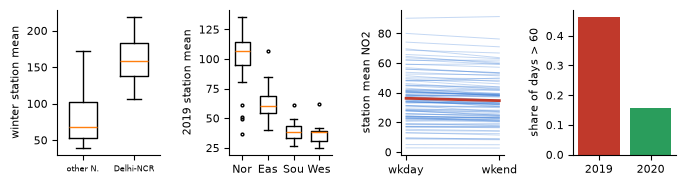

In [41]:
# summary figure of tests 2 to 5
fig, ax = plt.subplots(1, 4, figsize=(6.9, 1.9))

ax[0].boxplot([group_other, group_ncr], tick_labels=["other N.", "Delhi-NCR"], widths=0.55)
ax[0].set_ylabel("winter station mean")
ax[0].tick_params(axis="x", labelsize=6)

short_names = []
for name in region_names:
    short_names.append(name[:3])
ax[1].boxplot(groups, tick_labels=short_names, widths=0.6, flierprops=dict(markersize=2))
ax[1].set_ylabel("2019 station mean")

for i in range(len(weekday)):
    ax[2].plot([0, 1], [weekday[i], weekend[i]], color=BLUE, alpha=0.3, linewidth=0.7)
ax[2].plot([0, 1], [weekday.mean(), weekend.mean()], color=RED, linewidth=2)
ax[2].set_xticks([0, 1])
ax[2].set_xticklabels(["wkday", "wkend"])
ax[2].set_ylabel("station mean NO2")

ax[3].bar(["2019", "2020"], [share_2019, share_2020], color=[RED, GREEN])
ax[3].set_ylabel("share of days > 60")

plt.tight_layout()
plt.savefig("figs/fig_tests2.jpg", dpi=300)
plt.show()

**Test 5 result.** The share of days above 60 µg/m³ fell from about 46% to 15% (a drop of 31 percentage points, CI 29 to 32). Among days that changed, a day was about 8 times more likely to have improved than to have got worse. The drop is much bigger than the 10 point limit. McNemar is the right test because every 2020 day is matched with the same station and date in 2019.

## 6. Summary and multiple testing correction

In [42]:
test_names = [
    "T1 lockdown (paired t)",
    "T2 NCR vs North (Welch)",
    "T3 regions (Welch ANOVA)",
    "T4 weekend NO2 (paired t)",
    "T5 exceedance days (McNemar)",
]
raw_p_values = [R["T1"]["p"], R["T2"]["p"], R["T3"]["p"], R["T4"]["p"], R["T5"]["p"]]

# Holm correction for 5 tests, and simple Bonferroni
holm_p_values = multipletests(raw_p_values, method="holm")[1]
bonferroni_p_values = np.minimum(1, np.array(raw_p_values) * 5)

multi = []
for i in range(5):
    row = {
        "name": test_names[i],
        "p": float(raw_p_values[i]),
        "holm": float(holm_p_values[i]),
        "bonf": float(bonferroni_p_values[i]),
    }
    multi.append(row)
R["multi"] = multi

summary = pd.DataFrame(multi)
summary["reject at 0.05 (Holm)"] = summary["holm"] < 0.05
summary

,name,p,holm,bonf,reject at 0.05 (Holm)
0,T1 lockdown (paired t),8.645040e-21,3.458016e-20,4.322520e-20,True
1,T2 NCR vs North (Welch),6.120112e-04,6.120112e-04,3.060056e-03,True
2,T3 regions (Welch ANOVA),2.611654e-13,5.223308e-13,1.305827e-12,True
3,T4 weekend NO2 (paired t),1.631455e-17,4.894365e-17,8.157275e-17,True
4,T5 exceedance days (McNemar),0.000000e+00,0.000000e+00,0.000000e+00,True


In [43]:
# save every result in one json file
def to_plain(value):
    if hasattr(value, "item"):
        return value.item()
    return str(value)

with open("results.json", "w") as file:
    json.dump(R, file, indent=1, default=to_plain)

print("saved results.json and the figures in the figs folder")

saved results.json and the figures in the figs folder


## Conclusion
* **P1:** yes. PM2.5 fell by about 24 µg/m³ (38%) in the lockdown window, and this holds in every robustness check. It is much larger than the 10 µg/m³ that we said would matter.
* **P2:** yes. Winter PM2.5 at Delhi NCR is about 72 µg/m³ above other northern cities.
* **P3:** regions differ a lot (North about 102, East 68, South 39, West 38 µg/m³). South and West cannot be told apart.
* **P4:** weekend NO2 is only about 1.6 µg/m³ lower. Clearly real but too small to matter.
* **P5:** the share of days above 60 µg/m³ fell from 46% to 15%.

All five decisions stay the same after Holm correction. Main limitations: we cannot prove cause (weather also changed between 2019 and 2020), stations in the same city are not independent, and some groups have few stations.